# Give Me Some Credit: classify delinquency with a Random Forest

Train a Random Forest on the prepared credit data and inspect its held-out classification results. Complete the companion data-preparation notebook before running this lesson.

### Topics
- Load prepared training and test CSV files
- Select matching features
- Train a Random Forest classifier
- Interpret imbalanced-class metrics and prediction errors

**Question for the lesson:** Does the model detect delinquency effectively, beyond achieving high overall accuracy?

> **Estimated time: 30 min**

## 1 · Import the tools

Use Pandas to load prepared tables, a Random Forest classifier to predict delinquency, and classification metrics and Matplotlib to inspect errors. The imported splitting function is not used because the files already contain separate training and test subsets.

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

## 2 · Load the prepared training data

Run `give_me_some_credit.ipynb` first to generate `train.csv` and `test.csv` in this folder. Load the training export and inspect the columns, including the target and engineered repayment features.

In [2]:
train_data = pd.read_csv('train.csv')
train_data

,RevolvingUtilizationOfUnsecuredLines,age,SEX,EDUCATION,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,MonthlyIncome_missing,TotalPastDue,Has90DaysLate,WorstDelayStatus,Is_Outlier,SeriousDlqin
0,0.203223,60,1,2,0,1600.000000,5416.0,8,0,1,0,0.0,1,0,0,0,True,0
1,1.000000,24,0,3,0,0.100074,1358.0,3,0,0,0,0.0,0,0,0,0,False,0
2,0.200152,49,0,1,0,0.224416,12917.0,8,0,1,0,0.0,0,0,0,0,True,0
3,0.025735,78,1,1,0,347.000000,5416.0,7,0,0,0,0.0,1,0,0,0,True,0
4,0.133169,29,0,3,0,723.000000,5416.0,5,0,0,0,0.0,1,0,0,0,True,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
104792,0.962700,44,0,1,0,0.199446,7224.0,6,0,0,0,4.0,0,0,0,0,True,1
104793,0.000841,47,1,2,0,0.603267,4100.0,14,0,2,0,1.0,0,0,0,0,False,0
104794,0.039683,62,0,2,0,1945.000000,5416.0,13,0,1,0,0.0,1,0,0,0,True,0
104795,1.000000,33,0,3,0,3630.000000,0.0,6,0,2,0,1.0,0,0,0,0,True,0


## 3 · Load the prepared test data

This file contains the previously held-out rows, transformed using the training-set medians and matching feature definitions. Keep these rows out of model fitting.

In [3]:
test_data = pd.read_csv('test.csv')
test_data

,RevolvingUtilizationOfUnsecuredLines,age,SEX,EDUCATION,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,MonthlyIncome_missing,TotalPastDue,Has90DaysLate,WorstDelayStatus,SeriousDlqin
0,0.021663,61,1,3,0,0.500453,5516.0,8,0,2,0,0.0,0,0,0,0,0
1,0.000000,62,1,3,0,1461.000000,5416.0,14,0,1,0,0.0,1,0,0,0,0
2,0.060561,39,1,3,0,0.198144,12500.0,8,0,1,1,2.0,0,1,0,2,0
3,0.824374,30,0,2,0,0.100439,4330.0,4,0,0,0,0.0,0,0,0,0,0
4,1.000000,41,1,1,0,0.023712,10500.0,1,0,1,0,2.0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44908,0.170492,47,0,1,0,2443.000000,5416.0,9,0,1,0,1.0,1,0,0,0,0
44909,0.904568,49,1,2,2,2.158907,3586.0,16,0,6,0,0.0,0,2,0,1,1
44910,0.000000,53,0,3,0,0.537145,9058.0,9,0,2,0,1.0,0,0,0,0,0
44911,0.000000,31,0,2,0,343.000000,0.0,5,0,0,0,0.0,0,0,0,0,0


## 4 · Select training features and target

Use `SeriousDlqin` as the target: `1` indicates serious delinquency and `0` its absence. Remove it from the predictors along with `Is_Outlier`, a training-only diagnostic flag. All remaining predictors must be numerical and free of unsupported missing values.

In [4]:
X_train = train_data.drop(columns=['SeriousDlqin', "Is_Outlier"])
y_train = train_data['SeriousDlqin']

## 5 · Train a Random Forest classifier

Fit 100 trees using the prepared training rows. Each tree learns from a bootstrap sample and random feature subsets; the forest averages class probabilities to predict an outcome. `random_state=42` makes training reproducible. This example uses the default class weighting and prediction rule.

In [5]:
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
rf_classifier.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

## 6 · Prepare matching test inputs

Separate the test target from its predictors. Predictor names and order must match `X_train` exactly. The preparation notebook does not add `Is_Outlier` to test data, so only the target is dropped here. If you change either export, verify the two schemas before predicting.

In [6]:
X_test = test_data.drop(columns=['SeriousDlqin'])
y_test = test_data['SeriousDlqin']

## 7 · Evaluate delinquency predictions

Predict the held-out rows and inspect accuracy together with the per-class report. For delinquency (`1`), precision measures how many flagged customers actually have the outcome; recall measures how many actual delinquent customers are detected. F1 balances the two, and support counts the true examples of each class.

Compare accuracy with the majority-class share. A high accuracy can hide poor delinquency recall when class `1` is rare.

In [7]:
y_pred = rf_classifier.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
classification_rep = classification_report(y_test, y_pred)

print("Accuracy:", accuracy)
print("Classification Report:")
print(classification_rep)

Accuracy: 0.9362990670852537
Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.99      0.97     41950
           1       0.55      0.19      0.28      2963

    accuracy                           0.94     44913
   macro avg       0.75      0.59      0.62     44913
weighted avg       0.92      0.94      0.92     44913



## 8 · Interpret the confusion matrix

Rows are actual classes and columns are predicted classes. `Class 0` means no serious delinquency; `Class 1` means serious delinquency.

- Top left: correctly predicted non-delinquent customers.
- Top right: non-delinquent customers incorrectly flagged.
- Bottom left: delinquent customers the model missed.
- Bottom right: correctly detected delinquent customers.

### Pause & discuss

Which error is more costly in the intended lending workflow? How would that affect your choice of evaluation metric and decision threshold?

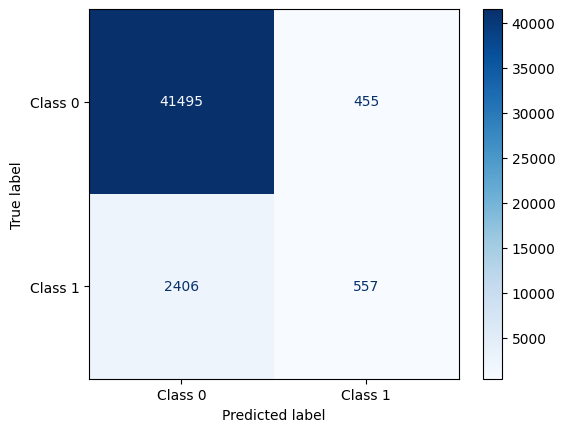

In [8]:
cm = confusion_matrix(y_test, y_pred)

# 2. Plot the matrix visually
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Class 0', 'Class 1'])
disp.plot(cmap=plt.cm.Blues)
plt.show()

## Key takeaways

- Fit the model on training rows and evaluate on held-out rows.
- Keep preprocessing and predictor schemas consistent across datasets.
- Inspect delinquency precision and recall alongside accuracy.
- Interpret errors in terms of the decisions they would affect.

### Try next

Compare these results with a majority-class baseline. As a separate experiment, use a validation subset of the training data to compare class weights or probability thresholds, then evaluate the chosen approach once on the test set.

--------------

assignment -- Aryan Hashemi

---------------

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

train_data = pd.read_csv('train.csv')
test_data = pd.read_csv('test.csv')

target = 'SeriousDlqin'

features = [
    col for col in train_data.columns
    if col not in [target, 'Is_Outlier']
]

X_train = train_data[features].copy()
y_train = train_data[target].astype(int)

X_test = test_data[features].copy()
y_test = test_data[target].astype(int)

assert 'NumberOfDefault' not in features
assert not any(col.startswith('Unnamed:') for col in features)
assert X_train.columns.equals(X_test.columns)
assert not X_train.isnull().any().any()
assert not X_test.isnull().any().any()

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("Features:", features)

Training rows: 104797
Test rows: 44913
Features: ['RevolvingUtilizationOfUnsecuredLines', 'age', 'SEX', 'EDUCATION', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents', 'MonthlyIncome_missing', 'TotalPastDue', 'Has90DaysLate', 'WorstDelayStatus']


In [10]:
class_distribution = pd.DataFrame({
    'Train count': y_train.value_counts(),
    'Train percent': y_train.value_counts(normalize=True) * 100,
    'Test count': y_test.value_counts(),
    'Test percent': y_test.value_counts(normalize=True) * 100
}).sort_index()

class_distribution.index.name = 'SeriousDlqin'

display(class_distribution.round(2))

,Train count,Train percent,Test count,Test percent
SeriousDlqin,,,,
0,97882,93.4,41950,93.4
1,6915,6.6,2963,6.6


In [11]:
dummy_model = DummyClassifier(strategy='most_frequent')
dummy_model.fit(X_train, y_train)

dummy_pred = dummy_model.predict(X_test)

rf_base = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_base.fit(X_train, y_train)

y_pred_base = rf_base.predict(X_test)

In [12]:
baseline_results = []

for name, predictions in [
    ('Majority baseline', dummy_pred),
    ('Random Forest baseline', y_pred_base)
]:

    baseline_results.append({
        'Model': name,
        'Test accuracy': accuracy_score(y_test, predictions),
        'Delinquency precision': precision_score(
            y_test, predictions, pos_label=1, zero_division=0
        ),
        'Delinquency recall': recall_score(
            y_test, predictions, pos_label=1, zero_division=0
        ),
        'Delinquency F1': f1_score(
            y_test, predictions, pos_label=1, zero_division=0
        ),
        'Delinquency support': int((y_test == 1).sum())
    })

baseline_comparison = pd.DataFrame(baseline_results)

display(baseline_comparison.round(4))

,Model,Test accuracy,Delinquency precision,Delinquency recall,Delinquency F1,Delinquency support
0,Majority baseline,0.9340,0.0000,0.000,0.0000,2963
1,Random Forest baseline,0.9363,0.5504,0.188,0.2803,2963


In [13]:
print(classification_report(
    y_test,
    y_pred_base,
    labels=[0, 1],
    target_names=['No serious delinquency', 'Serious delinquency'],
    digits=4,
    zero_division=0
))

                        precision    recall  f1-score   support

No serious delinquency     0.9452    0.9892    0.9667     41950
   Serious delinquency     0.5504    0.1880    0.2803      2963

              accuracy                         0.9363     44913
             macro avg     0.7478    0.5886    0.6235     44913
          weighted avg     0.9191    0.9363    0.9214     44913



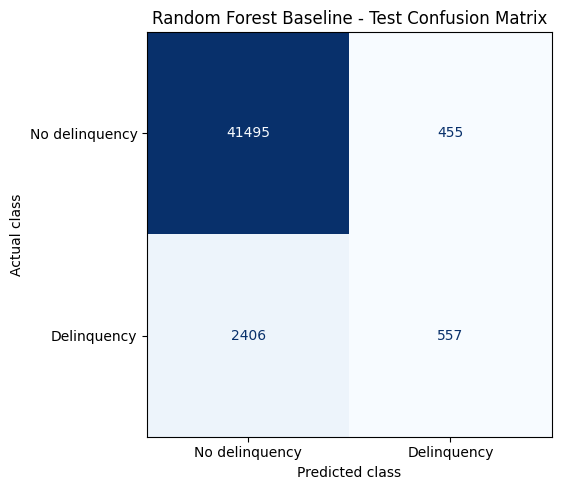

In [14]:
cm_base = confusion_matrix(
    y_test,
    y_pred_base,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_base,
    display_labels=['No delinquency', 'Delinquency']
)

fig, ax = plt.subplots(figsize=(7, 5))

disp.plot(
    ax=ax,
    cmap='Blues',
    values_format='d',
    colorbar=False
)

plt.title('Random Forest Baseline - Test Confusion Matrix')
plt.xlabel('Predicted class')
plt.ylabel('Actual class')
plt.tight_layout()
plt.show()

In [15]:
tn, fp, fn, tp = cm_base.ravel()

print("Correctly identified non-delinquent customers:", tn)
print("Non-delinquent customers incorrectly flagged:", fp)
print("Delinquent customers missed:", fn)
print("Correctly identified delinquent customers:", tp)

Correctly identified non-delinquent customers: 41495
Non-delinquent customers incorrectly flagged: 455
Delinquent customers missed: 2406
Correctly identified delinquent customers: 557


چون تعداد مشتری‌های بدون تأخیر جدی خیلی بیشتره، حتی پیش‌بینی همیشگی کلاس صفر هم
 accuracy 
 بالایی ایجاد می‌کنه. بنابراین کنار
  accuracy، به recall 
  کلاس یک نگاه می‌کنم تا مشخص بشه مدل چند درصد از موارد واقعی تأخیر رو پیدا کرده
  . Precision 
  هم نشون می‌ده چند درصد از مشتری‌هایی که مدل پرخطر تشخیص داده، واقعاً تأخیر جدی داشتن.

In [16]:
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier

credit = pd.read_csv('GiveMeSomeCredit.csv')

credit = credit[credit['age'].between(18, 100)].copy()

credit['SEX'] = credit['SEX'].map({'M': 0, 'F': 1})

credit = credit.drop(columns=['NumberOfDefault'])

credit['MonthlyIncome_missing'] = (
    credit['MonthlyIncome'].isna().astype(int)
)

credit['TotalPastDue'] = (
    credit['NumberOfTime30-59DaysPastDueNotWorse']
    + credit['NumberOfTime60-89DaysPastDueNotWorse']
    + credit['NumberOfTimes90DaysLate']
)

credit['Has90DaysLate'] = (
    credit['NumberOfTimes90DaysLate'] > 0
).astype(int)

credit['WorstDelayStatus'] = np.select(
    [
        credit['NumberOfTimes90DaysLate'] > 0,
        credit['NumberOfTime60-89DaysPastDueNotWorse'] > 0,
        credit['NumberOfTime30-59DaysPastDueNotWorse'] > 0
    ],
    [3, 2, 1],
    default=0
)

X_credit = credit.drop(columns=['SeriousDlqin'])
y_credit = credit['SeriousDlqin'].astype(int)

In [17]:
X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X_credit,
    y_credit,
    test_size=0.30,
    random_state=42,
    stratify=y_credit
)

X_fit, X_valid, y_fit, y_valid = train_test_split(
    X_train_raw,
    y_train_raw,
    test_size=0.25,
    random_state=42,
    stratify=y_train_raw
)

print("Model fitting rows:", len(X_fit))
print("Validation rows:", len(X_valid))
print("Test rows:", len(X_test_raw))

Model fitting rows: 78597
Validation rows: 26200
Test rows: 44913


In [18]:
outlier_columns = [
    'RevolvingUtilizationOfUnsecuredLines',
    'DebtRatio',
    'MonthlyIncome'
]

lower_bounds = X_fit[outlier_columns].quantile(0.005)
upper_bounds = X_fit[outlier_columns].quantile(0.995)

keep_rows = (
    (
        X_fit[outlier_columns].ge(lower_bounds)
        & X_fit[outlier_columns].le(upper_bounds)
    )
    | X_fit[outlier_columns].isna()
).all(axis=1)

outlier_bounds = pd.DataFrame({
    'Lower bound': lower_bounds,
    'Upper bound': upper_bounds
})

display(outlier_bounds)

print("Rows removed:", (~keep_rows).sum())
print("Classes among removed rows:")
print(y_fit.loc[~keep_rows].value_counts().sort_index())

,Lower bound,Upper bound
RevolvingUtilizationOfUnsecuredLines,0.0,1.395488
DebtRatio,0.0,6032.280000
MonthlyIncome,0.0,35000.000000


Rows removed: 1088
Classes among removed rows:
SeriousDlqin
0    947
1    141
Name: count, dtype: int64


In [19]:
rf_template = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

hist_template = HistGradientBoostingClassifier(
    max_iter=200,
    max_leaf_nodes=31,
    learning_rate=0.05,
    l2_regularization=3,
    early_stopping=False,
    random_state=42
)

# Name, Model, Undersampling, Remove outliers

experiments = [
    (
        'RF baseline',
        clone(rf_template),
        False, False
    ),
    (
        'RF undersampling',
        clone(rf_template),
        True, False
    ),
    (
        'RF outliers removed',
        clone(rf_template),
        False, True
    ),
    (
        'RF tuned + weights',
        clone(rf_template).set_params(
            n_estimators=200,
            max_depth=12,
            min_samples_leaf=5,
            class_weight='balanced_subsample'
        ),
        False, False
    ),
    (
        'HGB 100',
        clone(hist_template).set_params(
            max_iter=100,
            learning_rate=0.1,
            l2_regularization=1
        ),
        False, False
    ),
    (
        'HGB 200 small',
        clone(hist_template).set_params(
            max_leaf_nodes=15,
            l2_regularization=1
        ),
        False, False
    ),
    (
        'HGB 200 regularized',
        clone(hist_template),
        False, False
    ),
    (
        'HGB outliers removed',
        clone(hist_template),
        False, True
    ),
    (
        'HGB balanced weights',
        clone(hist_template).set_params(
            class_weight='balanced'
        ),
        False, False
    ),
    (
        'HGB undersampling',
        clone(hist_template),
        True, False
    )
]

In [20]:
validation_results = []

for index, experiment in enumerate(experiments):

    name, estimator, balance, remove_outliers = experiment

    X_current = X_fit.copy()
    y_current = y_fit.copy()

    if remove_outliers:
        X_current = X_current.loc[keep_rows]
        y_current = y_current.loc[keep_rows]

    if balance:
        positive_index = y_current[y_current == 1].index

        negative_index = y_current[y_current == 0].sample(
            n=min(
                int((y_current == 0).sum()),
                len(positive_index) * 3
            ),
            random_state=42
        ).index

        selected_index = positive_index.append(negative_index)

        X_current = X_current.loc[selected_index]
        y_current = y_current.loc[selected_index]

    current_model = make_pipeline(
        SimpleImputer(strategy='median'),
        clone(estimator)
    )

    current_model.fit(X_current, y_current)

    valid_pred = current_model.predict(X_valid)

    validation_results.append({
        'Experiment': index,
        'Model': name,
        'Fit rows': len(X_current),
        'Validation accuracy': accuracy_score(y_valid, valid_pred),
        'Delinquency precision': precision_score(
            y_valid, valid_pred, zero_division=0
        ),
        'Delinquency recall': recall_score(
            y_valid, valid_pred, zero_division=0
        ),
        'Delinquency F1': f1_score(
            y_valid, valid_pred, zero_division=0
        )
    })

    print("Finished:", name)

validation_table = pd.DataFrame(validation_results)

display(
    validation_table.sort_values(
        ['Validation accuracy', 'Delinquency F1'],
        ascending=False
    ).round(4)
)

Finished: RF baseline
Finished: RF undersampling
Finished: RF outliers removed
Finished: RF tuned + weights
Finished: HGB 100
Finished: HGB 200 small
Finished: HGB 200 regularized
Finished: HGB outliers removed
Finished: HGB balanced weights
Finished: HGB undersampling


,Experiment,Model,Fit rows,Validation accuracy,Delinquency precision,Delinquency recall,Delinquency F1
7,7,HGB outliers removed,77509,0.9378,0.5828,0.2036,0.3018
6,6,HGB 200 regularized,78597,0.9377,0.5845,0.1961,0.2936
5,5,HGB 200 small,78597,0.9376,0.5835,0.1880,0.2843
4,4,HGB 100,78597,0.9375,0.5786,0.1938,0.2903
2,2,RF outliers removed,77509,0.9353,0.5270,0.1978,0.2876
0,0,RF baseline,78597,0.9353,0.5261,0.1920,0.2814
9,9,HGB undersampling,20744,0.9011,0.3475,0.5674,0.4310
1,1,RF undersampling,20744,0.8974,0.3324,0.5506,0.4145
3,3,RF tuned + weights,78597,0.8624,0.2714,0.6437,0.3818
8,8,HGB balanced weights,78597,0.8105,0.2227,0.7513,0.3435


In [21]:
best_accuracy_index = int(
    validation_table.sort_values(
        ['Validation accuracy', 'Delinquency F1'],
        ascending=False
    ).iloc[0]['Experiment']
)

best_f1_index = int(
    validation_table.sort_values(
        ['Delinquency F1', 'Validation accuracy'],
        ascending=False
    ).iloc[0]['Experiment']
)

print(
    "Selected for accuracy:",
    experiments[best_accuracy_index][0]
)

print(
    "Selected for delinquency F1:",
    experiments[best_f1_index][0]
)

Selected for accuracy: HGB outliers removed
Selected for delinquency F1: HGB undersampling



Selection goal: Best validation accuracy
Model: HGB outliers removed
Undersampling: False
Remove outliers: True
Parameters: {'max_depth': None, 'min_samples_leaf': 20, 'max_features': 1.0, 'class_weight': None, 'max_iter': 200, 'max_leaf_nodes': 31, 'learning_rate': 0.05, 'l2_regularization': 3, 'early_stopping': False, 'random_state': 42}
                precision    recall  f1-score   support

No delinquency     0.9453    0.9899    0.9671     41950
   Delinquency     0.5706    0.1897    0.2847      2963

      accuracy                         0.9371     44913
     macro avg     0.7580    0.5898    0.6259     44913
  weighted avg     0.9206    0.9371    0.9221     44913



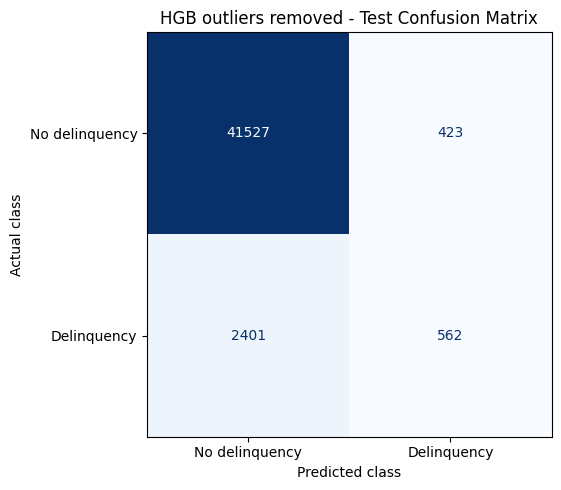


Selection goal: Best validation delinquency F1
Model: HGB undersampling
Undersampling: True
Remove outliers: False
Parameters: {'max_depth': None, 'min_samples_leaf': 20, 'max_features': 1.0, 'class_weight': None, 'max_iter': 200, 'max_leaf_nodes': 31, 'learning_rate': 0.05, 'l2_regularization': 3, 'early_stopping': False, 'random_state': 42}
                precision    recall  f1-score   support

No delinquency     0.9660    0.9284    0.9468     41950
   Delinquency     0.3463    0.5373    0.4212      2963

      accuracy                         0.9026     44913
     macro avg     0.6562    0.7328    0.6840     44913
  weighted avg     0.9251    0.9026    0.9121     44913



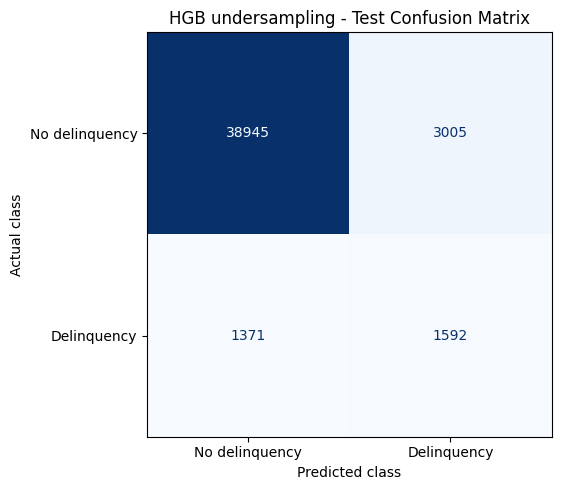

,Selection goal,Model,Test accuracy,Delinquency precision,Delinquency recall,Delinquency F1,Delinquency support
0,Best validation accuracy,HGB outliers removed,0.9371,0.5706,0.1897,0.2847,2963
1,Best validation delinquency F1,HGB undersampling,0.9026,0.3463,0.5373,0.4212,2963


In [22]:
selected_experiments = [
    ('Best validation accuracy', best_accuracy_index),
    ('Best validation delinquency F1', best_f1_index)
]

final_results = []

for goal, index in selected_experiments:

    name, estimator, balance, remove_outliers = experiments[index]

    X_final = X_train_raw.copy()
    y_final = y_train_raw.copy()

    if remove_outliers:
        lower = X_final[outlier_columns].quantile(0.005)
        upper = X_final[outlier_columns].quantile(0.995)

        final_keep = (
            (
                X_final[outlier_columns].ge(lower)
                & X_final[outlier_columns].le(upper)
            )
            | X_final[outlier_columns].isna()
        ).all(axis=1)

        X_final = X_final.loc[final_keep]
        y_final = y_final.loc[final_keep]

    if balance:
        positive_index = y_final[y_final == 1].index

        negative_index = y_final[y_final == 0].sample(
            n=min(
                int((y_final == 0).sum()),
                len(positive_index) * 3
            ),
            random_state=42
        ).index

        selected_index = positive_index.append(negative_index)

        X_final = X_final.loc[selected_index]
        y_final = y_final.loc[selected_index]

    final_model = make_pipeline(
        SimpleImputer(strategy='median'),
        clone(estimator)
    )

    final_model.fit(X_final, y_final)

    final_pred = final_model.predict(X_test_raw)

    final_results.append({
        'Selection goal': goal,
        'Model': name,
        'Test accuracy': accuracy_score(y_test_raw, final_pred),
        'Delinquency precision': precision_score(
            y_test_raw, final_pred, zero_division=0
        ),
        'Delinquency recall': recall_score(
            y_test_raw, final_pred, zero_division=0
        ),
        'Delinquency F1': f1_score(
            y_test_raw, final_pred, zero_division=0
        ),
        'Delinquency support': int((y_test_raw == 1).sum())
    })

    print("\nSelection goal:", goal)
    print("Model:", name)
    print("Undersampling:", balance)
    print("Remove outliers:", remove_outliers)

    parameters = estimator.get_params()

    parameter_names = [
        'n_estimators', 'max_depth', 'min_samples_leaf',
        'max_features', 'class_weight', 'max_iter',
        'max_leaf_nodes', 'learning_rate', 'l2_regularization',
        'early_stopping', 'random_state'
    ]

    print("Parameters:", {
        key: parameters[key]
        for key in parameter_names
        if key in parameters
    })

    print(classification_report(
        y_test_raw,
        final_pred,
        labels=[0, 1],
        target_names=['No delinquency', 'Delinquency'],
        digits=4,
        zero_division=0
    ))

    cm = confusion_matrix(y_test_raw, final_pred, labels=[0, 1])

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['No delinquency', 'Delinquency']
    )

    fig, ax = plt.subplots(figsize=(7, 5))

    disp.plot(
        ax=ax,
        cmap='Blues',
        values_format='d',
        colorbar=False
    )

    plt.title(f'{name} - Test Confusion Matrix')
    plt.xlabel('Predicted class')
    plt.ylabel('Actual class')
    plt.tight_layout()
    plt.show()

final_comparison = pd.DataFrame(final_results)

display(final_comparison.round(4))

روش منتخب از نظر دقت اعتبارسنجی، مدل زیر بعد از حذف داده‌های پرت شدید از آموزش بود:

HistGradientBoosting

این مدل با ۲۰۰ مرحله، حداکثر ۳۱ برگ، نرخ یادگیری ۰٫۰۵ و منظم‌سازی ۳، روی تست به دقت حدود ۹۳٫۷۱٪ رسید. این دقت کمی بیشتر از جنگل تصادفی پایه با ۹۳٫۶۳٪ بود، ولی فقط ۱۸٫۹۷٪ موارد واقعی تأخیر رو پیدا کرد؛ یعنی هنوز حدود ۸۱٪ این موارد رو تشخیص نداد.

روش منتخب از نظر معیار زیر، همین مدل با کم‌نمونه‌گیری کلاس صفر و بدون حذف داده‌های پرت بود:

F1-score

دقت تست این روش به ۹۰٫۲۶٪ کاهش پیدا کرد، اما نرخ کشف موارد واقعی تأخیر از ۱۸٫۸٪ مدل پایه به ۵۳٫۷۳٪ و معیار بالا از ۲۸٫۰۳٪ به ۴۲٫۱۲٪ رسید. البته فقط ۳۴٫۶۳٪ مشتری‌هایی که مدل دارای تأخیر تشخیص داده بود، واقعاً تأخیر داشتن؛ بنابراین هشدارهای اشتباه هم بیشتر شده.

در نتیجه، بهترین مدل به هدف ارزیابی بستگی داره: برای بیشترین دقت کلی، روش اول بهتر بود؛ اما برای پیدا‌کردن سهم بیشتری از مشتری‌های دارای تأخیر، روش متعادل‌شده عملکرد بهتری داشت. این نتایج نشون می‌دن در داده نامتوازن، دقت کلی بالا به‌تنهایی نشونه توانایی خوب مدل در تشخیص کلاس کم‌تعداد نیست.